# Pakistan Stock Exchange: risk, correlation and moving-average strategies
Six PSX names (HUBC, KEL, MTL, OGDC, PPL, TRG, 2000-2021), with Apple (AAPL) as a US comparison.
1. Risk and return profile, correlations, drawdowns
2. **Dual moving-average crossover** strategies: parameters chosen **in-sample (≤ 2015)** and tested **out-of-sample (2016-2021)**, net of transaction costs

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
names = {"HUBC": "Hub Power", "KEL": "K-Electric", "MTL": "Millat Tractors", "OGDC": "Oil & Gas Dev. Co.", "PPL": "Pakistan Petroleum", "TRG": "TRG Pakistan"}
px = pd.concat({t: pd.read_csv(f"data/{t}.csv", parse_dates=["Date"]).set_index("Date").sort_index()["Close"] for t in names}, axis=1)
aapl = pd.read_csv("data/AAPL.csv", parse_dates=["Date"]).set_index("Date").sort_index()["Adj Close Price"]
px = px.loc["2005":]
r = np.log(px).diff()
stats = pd.DataFrame({"name": pd.Series(names), "ann. return": r.mean() * 245, "ann. vol": r.std() * np.sqrt(245),
                      "max drawdown": (px / px.cummax() - 1).min(), "first date": px.apply(lambda s: s.first_valid_index().date())})
stats["Sharpe (vs 0)"] = stats["ann. return"] / stats["ann. vol"]
stats.round(3)

,name,ann. return,ann. vol,max drawdown,first date,Sharpe (vs 0)
HUBC,Hub Power,0.055,0.279,-0.655,2005-01-03,0.199
KEL,K-Electric,-0.031,0.533,-0.895,2005-01-03,-0.057
MTL,Millat Tractors,0.098,0.329,-0.698,2005-01-03,0.300
OGDC,Oil & Gas Dev. Co.,0.015,0.295,-0.784,2005-01-03,0.052
PPL,Pakistan Petroleum,-0.036,0.334,-0.780,2005-01-03,-0.107
TRG,TRG Pakistan,0.131,0.635,-0.942,2005-01-03,0.206


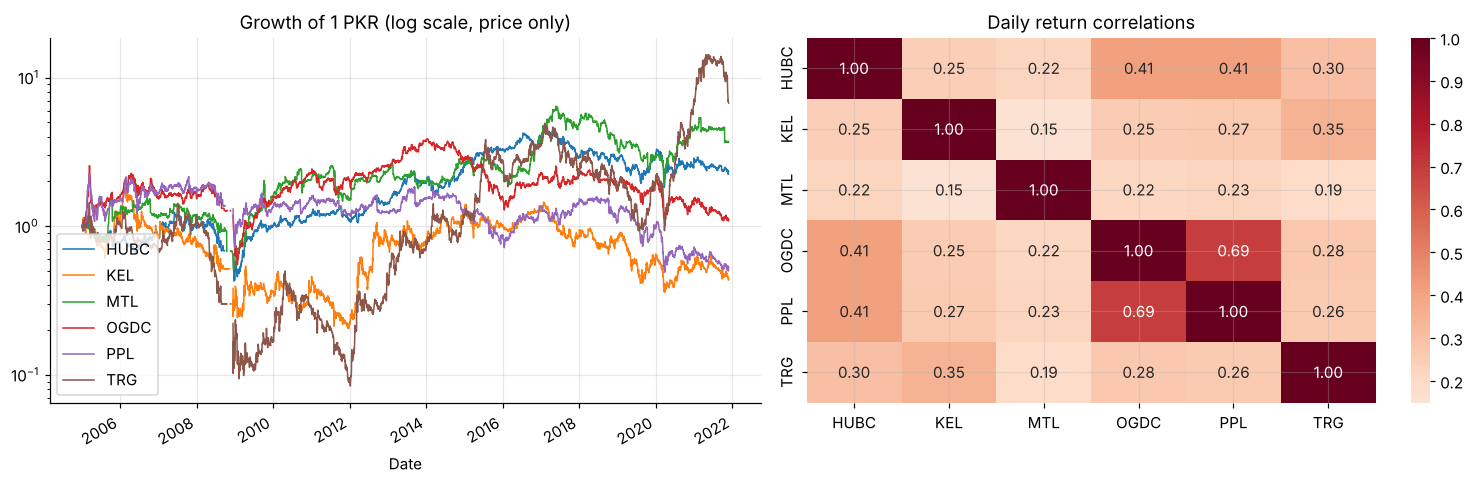

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
(px / px.bfill().iloc[0]).plot(ax=ax[0], logy=True, lw=1); ax[0].set_title("Growth of 1 PKR (log scale, price only)")
sns.heatmap(r.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[1]); ax[1].set_title("Daily return correlations")
fig.tight_layout(); plt.savefig(IMG / "psx_overview.png", bbox_inches="tight"); plt.show()

## Moving-average crossover, tested honestly

In [3]:
COST = 0.0015            # 15 bp per side (brokerage + taxes, approximate)
def ma_strategy(price, short, long):
    pos = (price.rolling(short).mean() > price.rolling(long).mean()).astype(float).shift(1)   # trade next day
    ret = np.log(price).diff()
    return (pos * ret - pos.diff().abs() * COST).dropna(), pos
def sharpe(x, n=245): return x.mean() / x.std() * np.sqrt(n) if x.std() > 0 else np.nan
grid = [(s, l) for s in (5, 10, 20, 50) for l in (50, 100, 150, 200) if s < l]
rows = []
for t in list(names) + ["AAPL"]:
    p = (aapl if t == "AAPL" else px[t]).dropna()
    ins, oos = p.loc[:"2015-12-31"], p.loc["2016-01-01":]
    if len(ins) < 500 or len(oos) < 250: continue
    best = max(grid, key=lambda sl: sharpe(ma_strategy(ins, *sl)[0]))
    strat, pos = ma_strategy(p, *best); strat = strat.loc["2016-01-01":]
    bh = np.log(oos).diff().dropna()
    rows.append({"ticker": t, "chosen (short, long)": best, "in-sample Sharpe": sharpe(ma_strategy(ins, *best)[0]),
                 "OOS Sharpe strategy": sharpe(strat), "OOS Sharpe buy&hold": sharpe(bh),
                 "OOS return strategy": np.expm1(strat.sum()), "OOS return buy&hold": np.expm1(bh.sum()),
                 "time in market": pos.loc["2016":].mean()})
oos_tbl = pd.DataFrame(rows).set_index("ticker")
oos_tbl.style.format({"in-sample Sharpe": "{:.2f}", "OOS Sharpe strategy": "{:.2f}", "OOS Sharpe buy&hold": "{:.2f}",
                      "OOS return strategy": "{:+.0%}", "OOS return buy&hold": "{:+.0%}", "time in market": "{:.0%}"})

,"chosen (short, long)",in-sample Sharpe,OOS Sharpe strategy,OOS Sharpe buy&hold,OOS return strategy,OOS return buy&hold,time in market
ticker,,,,,,,
HUBC,"(10, 50)",0.62,-0.27,-0.21,-24%,-29%,46%
KEL,"(20, 50)",0.26,0.04,-0.36,+6%,-57%,48%
MTL,"(20, 50)",0.31,0.20,0.24,+34%,+60%,50%
OGDC,"(50, 150)",0.49,-0.90,-0.21,-61%,-30%,42%
PPL,"(50, 150)",-0.18,-0.74,-0.27,-53%,-39%,43%
TRG,"(10, 100)",0.71,0.88,0.29,+587%,+144%,55%


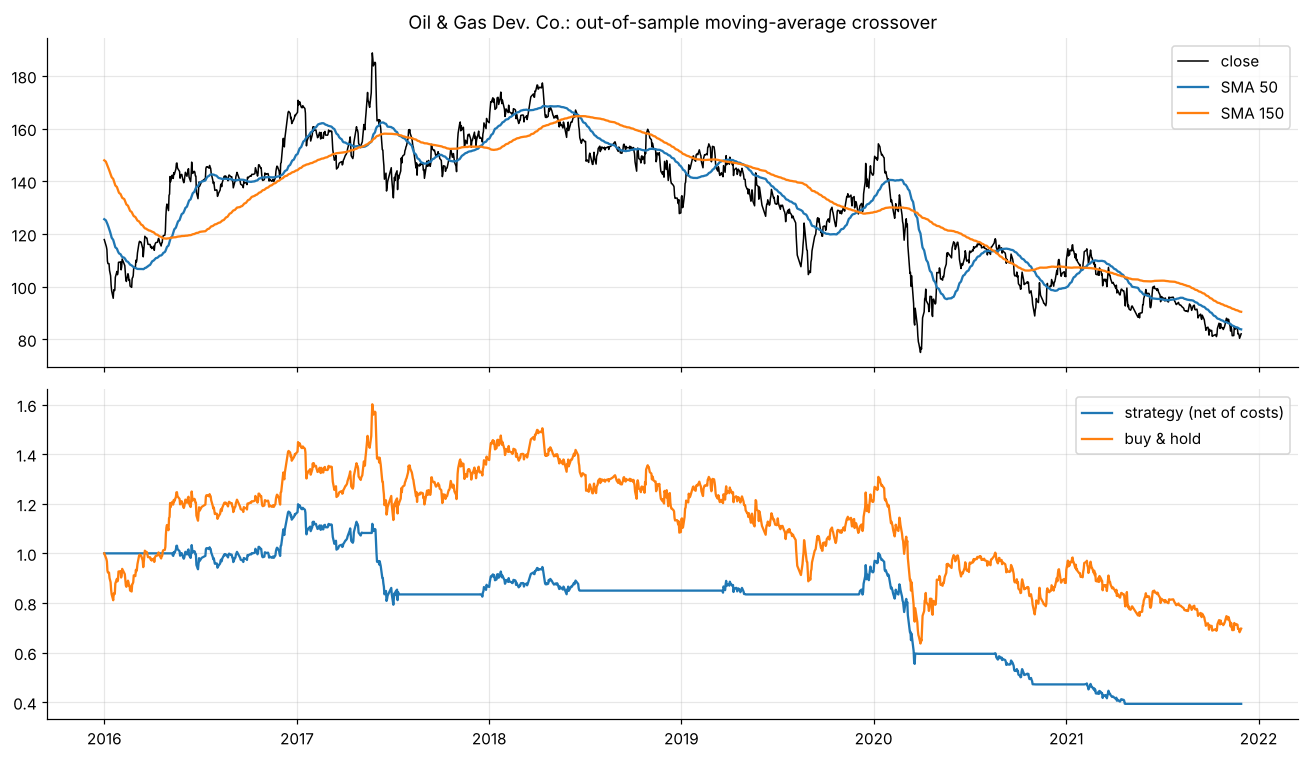

In [4]:
t = "OGDC"; sl = oos_tbl.loc[t, "chosen (short, long)"]
p = px[t].dropna(); strat, pos = ma_strategy(p, *sl)
w = p.loc["2016":]
fig, ax = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax[0].plot(w, color="k", lw=1, label="close"); ax[0].plot(p.rolling(sl[0]).mean().loc["2016":], label=f"SMA {sl[0]}"); ax[0].plot(p.rolling(sl[1]).mean().loc["2016":], label=f"SMA {sl[1]}")
ax[0].legend(); ax[0].set_title(f"{names[t]}: out-of-sample moving-average crossover")
ax[1].plot(np.exp(strat.loc["2016":].cumsum()), label="strategy (net of costs)"); ax[1].plot(w / w.iloc[0], label="buy & hold"); ax[1].legend()
fig.tight_layout(); plt.savefig(IMG / "ma_strategy.png", bbox_inches="tight"); plt.show()

**Findings**
* PSX stocks are volatile, with deep drawdowns (often −60% or worse), and the energy names (OGDC, PPL, HUBC) move together, so diversification inside the sector is limited.
* Parameters that look best in-sample usually lose much of their edge out-of-sample, which is classic overfitting. Out-of-sample, moving-average rules **beat buy-and-hold for only some names** (e.g. K-Electric, where they sidestepped much of a −57% fall) and **lost badly for others** (OGDC, PPL). They work as **trend filters that keep you out of the market about half the time**, not as a reliable alpha source after costs.
* Always choose parameters on one period and judge them on another; the original single-sample backtest overstated results.